# message的使用

## 1.消息格式

举例

In [4]:
# 初始化
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.messages.tool import tool_call

load_dotenv(override=True)

ARK_API_BASE = os.getenv("ARK_API_BASE")
ARK_API_KEY = os.getenv("ARK_API_KEY")

model = init_chat_model(
    model="glm-5-2-260617",
    model_provider="openai",
    base_url = ARK_API_BASE,
    api_key = ARK_API_KEY,
)

# json格式的信息
messages = [
    {"role":"system","content":"你说一个友好的AI助手"},
    {"role":"user","content":"1 + 2 = ？"},
    {"role":"assistant","content":"3"},
    {"role":"user","content":"我刚刚问了什么问题？"},
]
response = model.invoke(messages)
print(response)

content='你刚刚问了：“1 + 2 = ？”' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 261, 'prompt_tokens': 36, 'total_tokens': 297, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 250, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'glm-5-2-260617', 'system_fingerprint': None, 'id': '021790735215857682583ac3749be18cdf4b3a384433037af13bf', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a0f022-ea7a-74a1-8a7f-13cf2b983b9c-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 36, 'output_tokens': 261, 'total_tokens': 297, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 250}}


举例2：消息对象格式

In [2]:
from  langchain_core.messages import SystemMessage,HumanMessage,AIMessage
# 初始化
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

load_dotenv(override=True)

ARK_API_BASE = os.getenv("ARK_API_BASE")
ARK_API_KEY = os.getenv("ARK_API_KEY")

model = init_chat_model(
    model="glm-5-2-260617",
    model_provider="openai",
    base_url = ARK_API_BASE,
    api_key = ARK_API_KEY,
)
messages = [
    # {"role":"system","content":"你说一个友好的AI助手"},
     SystemMessage(content="你说一个友好的AI助手"),
    # {"role":"user","content":"1 + 2 = ？"},
    HumanMessage(content="1 + 2 = ？"),
    # {"role":"assistant","content":"3"},
    AIMessage(content="3"),
    # {"role":"user","content":"我刚刚问了什么问题？"},
    HumanMessage(content="我刚刚问了什么问题"),
]
response = model.invoke(messages)
print(response)



content='你刚刚问的是：“1 + 2 = ？”' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 360, 'prompt_tokens': 35, 'total_tokens': 395, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 348, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'glm-5-2-260617', 'system_fingerprint': None, 'id': '0217907642055567424dba2bd6e77b99d402060a9cf8c0f7485f6', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a0f1dd-450f-75b0-8b40-bee56c318719-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 35, 'output_tokens': 360, 'total_tokens': 395, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 348}}


举例3
SystemMessage参数列表
content：消息内容，字段名可以省略
HumanMessage参数列表
content：消息内容，字段名可以省略
metadata：元数据字段，可以又很多
HumanMessage(
    content:"Hello!",
    name:"alice", #可选，用户名
    id="msg_123", #可选，message的ID
)
name和id都属于元数据字段，当信息类型相同，对信息进行区分，但不是所有模型都支持这一功能，是否支持取决于模型供应商，需要查看官方手册

AIMessage参数列表
content：消息内容，字段名可以省略
response_metadata:AIMessage特有属性，LLM的响应中附加元数据，根据不同模型会有不同，如可能会包含本次token使用量等信息
tool_calls：AIMessage特有属性，表示工具调用信息。当LLM决定调用工具时，在AIMessage中就会包含这个属性，没有工具调用则为空，结构如下
这个就类似于MCP的功能
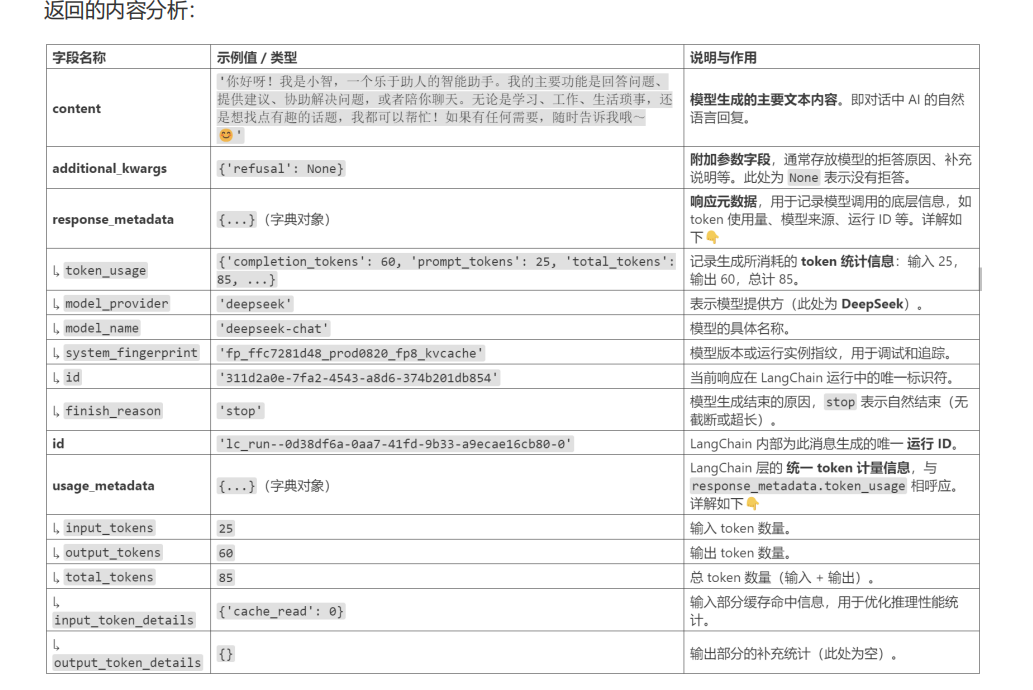

In [3]:
tool_call=[
    {
        'name':'get_weather', #应调用的工具名
        'args':{'city':'杭州'}, # 调用工具的参数
        'id':'call_00_gIXYOD1Q1OkEXmdDBqXR1578', # 工具调用的唯一标识ID
        'type':'tool_call',
    },
    {
        'name':'get_news',
        'args':{},
        'id':'call_01_jD3phD5PEaIZf0mVLhKt0861',
        'type':'tool_call',
    }
]

### ToolMessage参数列表
content:文件内容
name:工具名称
tool_call_id:工具调用唯一ID，ToolMessage必须紧邻匹配的AIMessage，和前者tool_calls中的id一致
ToolMessage(
    content="<工具输出>",
    name="get_weather",
    tool_call_id="call_00_nUD2NC9QRN5Cg1GaoIkBJQ4s" # 一定要和AI信息中的调用ID匹配
)

举例

In [7]:
load_dotenv(override=True)
ARK_API_BASE = os.getenv("ARK_API_BASE")
ARK_API_KEY = os.getenv("ARK_API_KEY")

model = init_chat_model(
    model="glm-5-2-260617",
    model_provider="openai",
    base_url = ARK_API_BASE,
    api_key = ARK_API_KEY,
)
# tool_calls=[
# {
# 'name': 'get_weather', # 应调用的工具名
# 'args': {'city': '南昌'}, # 调用工具的参数
# 'id': 'call_00_gIXYOD1Q1OkEXmdDBqXR1578', # 工具调用的唯一标识ID
# 'type': 'tool_call'
# },
# {'name': 'get_news',
# 'args': {},
# 'id': 'call_01_jD3phD5PEaIZf0mVLhKt0861',
# 'type': 'tool_call'
# }
# ]
def get_weather(city: str) -> str:
    return "不错噢~~~"
# 模拟模型绑定工具
model_with_tools = model.bind_tools([get_weather])
ai_message = {
    "role":"assistant",
    "content":"",
    "tool_calls":[{
        "name":"get_weather",
        "args":{"location":"南昌"},
        "id":"call_00_nUD2NC9QRN5Cg1GaoIkBJQ4s"
    }]
}

tool_message = {
    "role":"tool",
    "content":"今天南昌天气多云~~~~~",
    "tool_calls_id":"call_00_nUD2NC9QRN5Cg1GaoIkBJQ4s",
}

messages = [
    {"role":"user","content":"南昌天气如何"},
    ai_message,
    tool_message,
]
response = model.invoke(messages)
print(response)

KeyError: 'tool_call_id'